# Прогноз риска повторного обращения в течение 30 дней после ремонта

Аспирант: Фрелих И. П. (СамГТУ, специальность 2.5.22). Научный руководитель: Мосин В. Г., д.т.н., к.ф.-м.н., доцент.

**Производственная проблема.** После ремонта клиент может вернуться в течение 30 дней с той же неисправностью:
недоделанный ремонт, ошибка диагностики, брак запчасти. Повторное обращение снижает лояльность клиента (NPS)
и добавляет работу сервису.

**Что хотим получить.** Модель, которая в момент закрытия заказ-наряда оценивает вероятность повторного обращения.
Для заказ-нарядов с высоким риском назначается усиленный контроль качества: дополнительная проверка, тест-драйв,
расширенная гарантия.

**Данные.** Файл `data/service_repeat_visit_dataset.csv` из постановки задачи (`Задача.pdf`) — 3 000 заказ-нарядов.

| Признак | Смысл | Тип / диапазон |
|---|---|---|
| `repair_complexity_score` | оценка сложности ремонта по внутренней шкале сервиса | дробное, 1–10 |
| `labor_hours` | фактические нормо-часы работ | дробное, 0,5–20 |
| `num_parts_installed` | количество установленных запчастей | целое, 1–15 |
| `diagnostic_accuracy_flag` | первоначальный диагноз подтвердился в ходе работ (1) или нет (0) | 0/1 |
| `technician_experience_years` | стаж мастера, лет | дробное, 1–30 |
| `vehicle_brand_segment` | сегмент автомобиля: 1 — эконом, 2 — средний, 3 — премиум | 1–3 |
| `repeat_visit_within_30d` | **целевой признак**: 1 — клиент вернулся с той же проблемой в течение 30 дней | 0/1 |

**План работы:** проверка данных → мэппинг кодов → сравнение двух способов прогноза на 100 случайных разбиениях →
влияние факторов → выбор порога для усиленного контроля → практические выводы.

## 1. Подключение библиотек

Используем только стандартный набор: `pandas` и `numpy` для таблиц, `matplotlib` для графиков,
`scikit-learn` для моделей и метрик.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, brier_score_loss, recall_score,
                             precision_score, f1_score, accuracy_score)

## 2. Загрузка данных

Источник: `data/service_repeat_visit_dataset.csv` (лежит в одной папке с ноутбуком). Одна строка — один закрытый заказ-наряд.

In [2]:
df = pd.read_csv("data/service_repeat_visit_dataset.csv")

print("Строк:", df.shape[0], "| столбцов:", df.shape[1])
display(df.head())

Строк: 3000 | столбцов: 7


,repair_complexity_score,labor_hours,num_parts_installed,diagnostic_accuracy_flag,technician_experience_years,vehicle_brand_segment,repeat_visit_within_30d
0,4.37,13.62,5,1,29.8,2,0
1,9.56,16.04,3,1,6.3,2,0
2,7.59,5.38,7,1,7.2,2,0
3,6.39,12.69,4,1,9.4,3,0
4,2.40,11.65,2,0,29.3,3,0


## 3. Проверка данных

Перед расчётами убеждаемся, что в данных нет пропусков и дубликатов, а значения не выходят за диапазоны,
указанные в постановке задачи. Если хотя бы одна строка таблицы покажет `False`, данные нужно чистить.

In [3]:
# Допустимые диапазоны из постановки задачи (Задача.pdf)
expected_range = {
    "repair_complexity_score": (1, 10),
    "labor_hours": (0.5, 20),
    "num_parts_installed": (1, 15),
    "diagnostic_accuracy_flag": (0, 1),
    "technician_experience_years": (1, 30),
    "vehicle_brand_segment": (1, 3),
    "repeat_visit_within_30d": (0, 1),
}

check = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "минимум": df.min(),
    "максимум": df.max(),
    "допустимый минимум": [expected_range[col][0] for col in df.columns],
    "допустимый максимум": [expected_range[col][1] for col in df.columns],
})
check["в диапазоне"] = ((check["минимум"] >= check["допустимый минимум"])
                        & (check["максимум"] <= check["допустимый максимум"]))
display(check)

print("Полных дубликатов строк:", df.duplicated().sum())

,пропусков,минимум,максимум,допустимый минимум,допустимый максимум,в диапазоне
repair_complexity_score,0,1.0,10.00,1.0,10,True
labor_hours,0,0.5,19.99,0.5,20,True
num_parts_installed,0,1.0,11.00,1.0,15,True
diagnostic_accuracy_flag,0,0.0,1.00,0.0,1,True
technician_experience_years,0,1.0,30.00,1.0,30,True
vehicle_brand_segment,0,1.0,3.00,1.0,3,True
repeat_visit_within_30d,0,0.0,1.00,0.0,1,True


Полных дубликатов строк: 0


## 4. Мэппинг кодов и названий

В данных сегмент автомобиля и результат диагностики записаны числовыми кодами. Для таблиц и графиков переводим
коды в понятные слова по таблицам соответствий. Модели при этом работают с исходными числовыми кодами.

Здесь же задаём русские названия признаков и единицы их изменения — они понадобятся в таблице влияния факторов.

In [4]:
d_segment = {1: "эконом", 2: "средний", 3: "премиум"}
d_diagnosis = {0: "не подтвердилась", 1: "подтвердилась"}

df["сегмент"] = df["vehicle_brand_segment"].map(d_segment)
df["диагностика"] = df["diagnostic_accuracy_flag"].map(d_diagnosis)

# Русские названия признаков
d_names = {
    "repair_complexity_score": "Сложность ремонта",
    "labor_hours": "Трудоёмкость",
    "num_parts_installed": "Число запчастей",
    "diagnostic_accuracy_flag": "Диагноз подтвердился",
    "technician_experience_years": "Стаж мастера",
    "vehicle_brand_segment": "Сегмент автомобиля",
}

# На сколько меняется признак, к которому относится отношение шансов в разделе 9
d_units = {
    "repair_complexity_score": "+1 балл",
    "labor_hours": "+1 нормо-час",
    "num_parts_installed": "+1 запчасть",
    "diagnostic_accuracy_flag": "нет → да",
    "technician_experience_years": "+1 год",
    "vehicle_brand_segment": "+1 ступень",
}

display(df[["vehicle_brand_segment", "сегмент", "diagnostic_accuracy_flag", "диагностика"]].head())

,vehicle_brand_segment,сегмент,diagnostic_accuracy_flag,диагностика
0,2,средний,1,подтвердилась
1,2,средний,1,подтвердилась
2,2,средний,1,подтвердилась
3,3,премиум,1,подтвердилась
4,3,премиум,0,не подтвердилась


## 5. Доля повторных обращений

Смотрим, как часто клиенты возвращаются в целом и в разных группах заказ-нарядов. Это первый, ещё без модели,
взгляд на то, какие факторы связаны с повторным обращением.

In [5]:
target = "repeat_visit_within_30d"

print("Всего заказ-нарядов:", len(df))
print("Повторных обращений:", df[target].sum(), f"({df[target].mean():.1%})")

Всего заказ-нарядов: 3000
Повторных обращений: 1014 (33.8%)


Теперь те же доли по группам: подтвердился ли первоначальный диагноз и какой сегмент у автомобиля.

In [6]:
by_diagnosis = df.groupby("диагностика")[target].agg(["count", "mean"])
by_diagnosis.columns = ["заказ-нарядов", "доля повторных обращений"]
display(by_diagnosis.round(3))

by_segment = df.groupby("vehicle_brand_segment")[target].agg(["count", "mean"])
by_segment.index = by_segment.index.map(d_segment)
by_segment.columns = ["заказ-нарядов", "доля повторных обращений"]
display(by_segment.round(3))

,заказ-нарядов,доля повторных обращений
диагностика,,
не подтвердилась,949,0.747
подтвердилась,2051,0.149


,заказ-нарядов,доля повторных обращений
vehicle_brand_segment,,
эконом,1507,0.301
средний,1068,0.357
премиум,425,0.424


Доля повторных обращений растёт от эконом-сегмента к премиуму примерно равными шагами. Поэтому сегмент можно
подавать в модель одним числом 1–3, не разбивая на отдельные признаки.

Отдельно смотрим сочетание сложности ремонта и стажа мастера — это нужно для практической рекомендации
о распределении работ между мастерами.

In [7]:
complexity_group = pd.cut(df["repair_complexity_score"], bins=[0, 4, 7, 10],
                          labels=["сложность 1–4", "сложность 4–7", "сложность 7–10"])
experience_group = pd.cut(df["technician_experience_years"], bins=[0, 5, 10, 20, 30],
                          labels=["стаж до 5 лет", "5–10 лет", "10–20 лет", "20–30 лет"])

# Доля повторных обращений в каждой клетке «сложность × стаж»
complexity_vs_experience = df.groupby([complexity_group, experience_group], observed=True)[target].mean().unstack()
display(complexity_vs_experience.round(2))

technician_experience_years,стаж до 5 лет,5–10 лет,10–20 лет,20–30 лет
repair_complexity_score,,,,
сложность 1–4,0.27,0.23,0.18,0.09
сложность 4–7,0.47,0.39,0.36,0.26
сложность 7–10,0.67,0.63,0.46,0.42


## 6. Признаки и целевая переменная

В модель идут все шесть признаков. Все они известны на момент закрытия заказ-наряда, то есть модель можно
применять до выдачи автомобиля клиенту.

In [8]:
features = [
    "repair_complexity_score",
    "labor_hours",
    "num_parts_installed",
    "diagnostic_accuracy_flag",
    "technician_experience_years",
    "vehicle_brand_segment",
]

X = df[features]
y = df[target]

## 7. Сравнение способов А и B на 100 разбиениях

Одно разбиение на обучающую и тестовую части нестабильно: результат зависит от того, какие заказ-наряды
случайно попали в тест. Поэтому делаем **100 запусков** с `random_state = 0, 1, …, 99` и берём средние значения.
Разбиение стратифицированное (`stratify=y`), чтобы в каждой тестовой выборке доля возвратов была такой же, как в данных (≈34 %).

- **Способ А — логистическая регрессия.** Даёт вероятность возврата и понятные коэффициенты.
  Признаки приводим к одному масштабу (`StandardScaler`), причём среднее и разброс считаем **только по обучающей части**,
  иначе информация из теста просочится в обучение.
- **Способ B — случайный лес** (100 деревьев, глубина не больше 6). Умеет находить нелинейные зависимости.
  Масштабирование ему не нужно. Глубину деревьев ограничиваем 6 уровнями, чтобы лес не переобучался.

**Метрики** (на тестовой части каждого запуска):
- **ROC-AUC** — главная: насколько хорошо модель ставит рискованные заказ-наряды выше безопасных (0,5 — угадывание, 1 — идеал);
- **Brier** — средняя квадратичная ошибка вероятности (чем меньше, тем точнее сама вероятность);
- **Recall, Precision, F1, Accuracy** — при пороге 0,5: какая доля возвратов поймана, какая доля тревог подтвердилась и т. д.

Сначала запишем расчёт метрик в небольшую функцию, чтобы не повторять один и тот же код для двух способов.

In [9]:
def quality(y_true, prob, threshold=0.5):
    # prob — предсказанная вероятность возврата; pred — решение «назначить контроль» при заданном пороге
    pred = (prob >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "Recall": recall_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "Accuracy": accuracy_score(y_true, pred),
    }

Цикл из 100 запусков. В каждом запуске оба способа обучаются на одной и той же обучающей части и проверяются
на одной и той же тестовой — так сравнение честное. Результаты складываем в таблицу `results`.

In [10]:
rows = []

for seed in range(100):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)

    # Способ А: логистическая регрессия.
    # Масштабирование настраиваем только на обучающей части (без утечки данных из теста)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model_A = LogisticRegression(max_iter=1000)
    model_A.fit(X_train_scaled, y_train)
    prob_A = model_A.predict_proba(X_test_scaled)[:, 1]

    result_A = quality(y_test, prob_A)
    result_A["способ"] = "А: логистическая регрессия"
    result_A["запуск"] = seed
    rows.append(result_A)

    # Способ B: случайный лес
    model_B = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=seed)
    model_B.fit(X_train, y_train)
    prob_B = model_B.predict_proba(X_test)[:, 1]

    result_B = quality(y_test, prob_B)
    result_B["способ"] = "B: случайный лес"
    result_B["запуск"] = seed
    rows.append(result_B)

results = pd.DataFrame(rows)
print("Выполнено запусков:", results["запуск"].nunique())

Выполнено запусков: 100


## 8. Итоговая таблица: среднее и стандартное отклонение по 100 запускам

In [11]:
metrics = ["ROC-AUC", "Brier", "Recall", "Precision", "F1", "Accuracy"]

summary = results.groupby("способ")[metrics].agg(["mean", "std"]).T
summary = summary[["А: логистическая регрессия", "B: случайный лес"]]  # способ А первым столбцом
summary.index.names = ["метрика", "показатель"]
display(summary.round(4))

способ                А: логистическая регрессия  B: случайный лес
метрика   показатель                                              
ROC-AUC   mean                            0.9202            0.9135
          std                             0.0111            0.0122
Brier     mean                            0.0993            0.1048
          std                             0.0071            0.0069
Recall    mean                            0.7566            0.6900
          std                             0.0322            0.0341
Precision mean                            0.8347            0.8730
          std                             0.0260            0.0256
F1        mean                            0.7932            0.7702
          std                             0.0219            0.0247
Accuracy  mean                            0.8667            0.8610
          std                             0.0134            0.0135

Средние значения близки, поэтому дополнительно сравниваем способы **попарно**: в каждом запуске оба способа
проверялись на одной и той же тестовой выборке, значит можно посчитать, в скольких запусках из 100 способ А оказался лучше.

In [12]:
res_A = results[results["способ"] == "А: логистическая регрессия"]
res_B = results[results["способ"] == "B: случайный лес"]

# Строки обоих способов идут в одном порядке запусков (0..99), поэтому значения можно сравнивать попарно
auc_diff = res_A["ROC-AUC"].values - res_B["ROC-AUC"].values
brier_diff = res_A["Brier"].values - res_B["Brier"].values

print("ROC-AUC:  средняя разница А − B =", round(auc_diff.mean(), 4),
      "| А лучше в", (auc_diff > 0).sum(), "запусках из 100")
print("Brier:    средняя разница А − B =", round(brier_diff.mean(), 4),
      "| А лучше (ошибка меньше) в", (brier_diff < 0).sum(), "запусках из 100")

ROC-AUC:  средняя разница А − B = 0.0066 | А лучше в 97 запусках из 100
Brier:    средняя разница А − B = -0.0055 | А лучше (ошибка меньше) в 99 запусках из 100


## 9. Влияние факторов: отношения шансов

Чтобы объяснить инженеру, **почему** модель считает заказ-наряд рискованным, обучаем логистическую регрессию
на всех 3 000 заказ-нарядах. Эта модель нужна только для объяснения факторов; качество прогноза мы уже оценили в разделах 7–8.

- Признаки берём **в исходных единицах** (баллы, часы, годы), чтобы результат читался просто:
  «каждый дополнительный балл сложности увеличивает шансы возврата в … раза».
- Регуляризацию отключаем (`C=np.inf`): она слегка занижает коэффициенты, а для объяснения факторов нужны несмещённые оценки.
- **Отношение шансов (OR)** = $e^{\beta}$. OR > 1 — фактор повышает шансы возврата, OR < 1 — снижает.
  Шансы — это отношение «вернулся / не вернулся»; при доле возвратов 34 % шансы равны 0,34 / 0,66 ≈ 0,5.
- 95 %-й доверительный интервал считаем по стандартным ошибкам коэффициентов (так же их считает пакет `statsmodels`).
  Если интервал не накрывает 1, влияние фактора статистически значимо.
- Чтобы сравнить силу факторов с разными единицами, дополнительно приводим OR при изменении признака на одно
  стандартное отклонение.

In [13]:
model_full = LogisticRegression(C=np.inf, max_iter=5000)
model_full.fit(X, y)
beta = model_full.coef_[0]

# Стандартные ошибки коэффициентов: корни диагонали обратной матрицы X^T W X,
# где W — веса p·(1 − p) для каждого заказ-наряда
p = model_full.predict_proba(X)[:, 1]
X_with_const = np.column_stack([np.ones(len(X)), X.values])  # столбец единиц — для свободного члена
cov_matrix = np.linalg.inv(X_with_const.T @ (X_with_const * (p * (1 - p))[:, None]))
se = np.sqrt(np.diag(cov_matrix))[1:]  # свободный член не нужен

Собираем таблицу: отношение шансов, его 95 %-й интервал и сила влияния фактора. Строки отсортированы от самого сильного фактора к самому слабому.

In [14]:
factors = pd.DataFrame({
    "фактор": [d_names[f] for f in features],
    "изменение": [d_units[f] for f in features],
    "OR": np.exp(beta),
    "OR: нижняя граница 95%": np.exp(beta - 1.96 * se),
    "OR: верхняя граница 95%": np.exp(beta + 1.96 * se),
    "OR на 1 ст. отклонение": np.exp(beta * X.std().values),
})

# Сортируем по силе влияния: |β · σ| — изменение логарифма шансов при сдвиге фактора на одно стандартное отклонение
factors["сила влияния |β·σ|"] = np.abs(beta * X.std().values)
factors = factors.sort_values("сила влияния |β·σ|", ascending=False)
display(factors.round(3))

d_flag = factors.set_index("фактор").loc["Диагноз подтвердился"]
print("Если диагноз НЕ подтвердился, шансы возврата выше в", round(1 / d_flag["OR"]), "раз",
      f"(95% интервал: {1 / d_flag['OR: верхняя граница 95%']:.0f}–{1 / d_flag['OR: нижняя граница 95%']:.0f})")

,фактор,изменение,OR,OR: нижняя граница 95%,OR: верхняя граница 95%,OR на 1 ст. отклонение,сила влияния |β·σ|
3,Диагноз подтвердился,нет → да,0.011,0.008,0.015,0.123,2.096
0,Сложность ремонта,+1 балл,1.812,1.709,1.921,4.760,1.560
4,Стаж мастера,+1 год,0.919,0.906,0.933,0.493,0.708
1,Трудоёмкость,+1 нормо-час,1.107,1.085,1.131,1.772,0.572
5,Сегмент автомобиля,+1 ступень,1.674,1.432,1.957,1.447,0.369
2,Число запчастей,+1 запчасть,1.162,1.089,1.240,1.296,0.260


Если диагноз НЕ подтвердился, шансы возврата выше в 91 раз (95% интервал: 65–126)


## 10. Проверка: какие факторы важны для случайного леса

Независимая проверка порядка факторов: если случайный лес (способ B) выделяет те же главные факторы,
что и регрессия, выводы раздела 9 не зависят от выбранного метода.

In [15]:
model_B_full = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=0)
model_B_full.fit(X, y)

importance = pd.DataFrame({
    "фактор": [d_names[f] for f in features],
    "важность в случайном лесе": model_B_full.feature_importances_,
}).sort_values("важность в случайном лесе", ascending=False)
display(importance.round(3))

,фактор,важность в случайном лесе
3,Диагноз подтвердился,0.575
0,Сложность ремонта,0.243
4,Стаж мастера,0.078
1,Трудоёмкость,0.065
2,Число запчастей,0.022
5,Сегмент автомобиля,0.017


## 11. Выбор порога для усиленного контроля

Модель выдаёт вероятность возврата, а мастеру нужно решение «проверять / не проверять». Решение зависит от порога:
если вероятность ≥ порога, заказ-наряд отправляется на усиленный контроль. Низкий порог ловит больше будущих возвратов,
но и проверять приходится больше машин.

Таблицу считаем тоже по 100 разбиениям (способ А) и выражаем **на 100 закрытых заказ-нарядов** — так её проще применить
к загрузке поста контроля. Без модели, при выборочной проверке, доля пойманных возвратов равна доле проверенных машин.

In [16]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_rows = []

for seed in range(100):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model_A = LogisticRegression(max_iter=1000)
    model_A.fit(X_train_scaled, y_train)
    prob_A = model_A.predict_proba(X_test_scaled)[:, 1]

    returned = y_test.values == 1              # True — клиент на самом деле вернулся
    n = len(y_test)                            # размер тестовой выборки (600 заказ-нарядов)

    for t in thresholds:
        to_check = prob_A >= t                 # True — машина идёт на усиленный контроль
        threshold_rows.append({
            "порог": t,
            "проверяем, машин из 100": to_check.sum() / n * 100,
            "из них вернулись бы": (to_check & returned).sum() / n * 100,
            "пропущено возвратов из 100": (~to_check & returned).sum() / n * 100,
            "поймано возвратов, %": (to_check & returned).sum() / returned.sum() * 100,
        })

threshold_table = pd.DataFrame(threshold_rows).groupby("порог").mean()
display(threshold_table.round(1))

,"проверяем, машин из 100",из них вернулись бы,пропущено возвратов из 100,"поймано возвратов, %"
порог,,,,
0.20,48.6,30.6,3.3,90.4
0.25,44.7,29.8,4.0,88.1
0.30,41.3,29.2,4.7,86.2
0.35,38.4,28.3,5.5,83.7
0.40,35.8,27.5,6.3,81.3
0.45,33.1,26.5,7.3,78.4
0.50,30.7,25.6,8.2,75.7
0.55,28.3,24.4,9.5,72.0
0.60,26.2,23.1,10.7,68.4


## 12. Графики

Рисунки сохраняются в папку `pictures` (300 dpi) для вставки в статью.

**Рисунок 1.** Разброс ROC-AUC двух способов по 100 запускам.

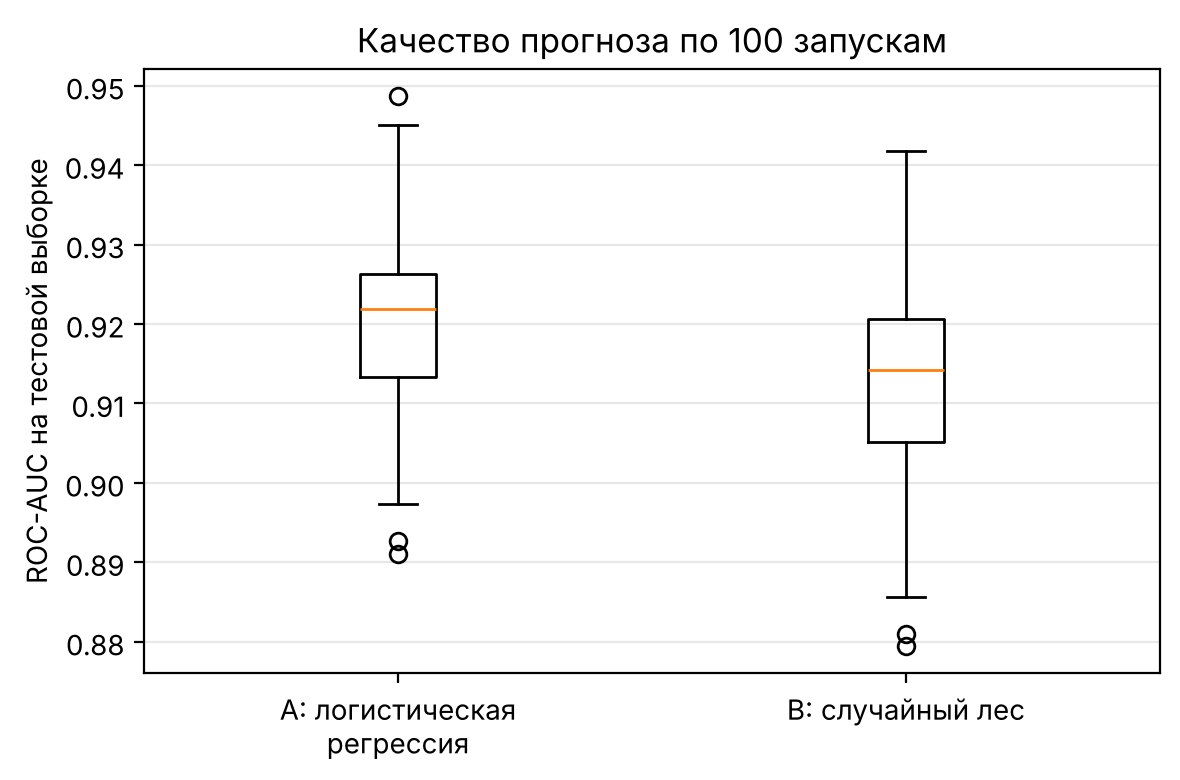

In [17]:
os.makedirs("pictures", exist_ok=True)

plt.figure(figsize=(6, 4))
plt.boxplot([res_A["ROC-AUC"], res_B["ROC-AUC"]])
plt.xticks([1, 2], ["А: логистическая\nрегрессия", "B: случайный лес"])
plt.ylabel("ROC-AUC на тестовой выборке")
plt.title("Качество прогноза по 100 запускам")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("pictures/fig1_auc_100_runs.png", dpi=300)
plt.show()

**Рисунок 2.** Сила влияния факторов: отношение шансов при изменении фактора на одно стандартное отклонение
(логарифмическая шкала; правее 1 — фактор повышает риск, левее — снижает).

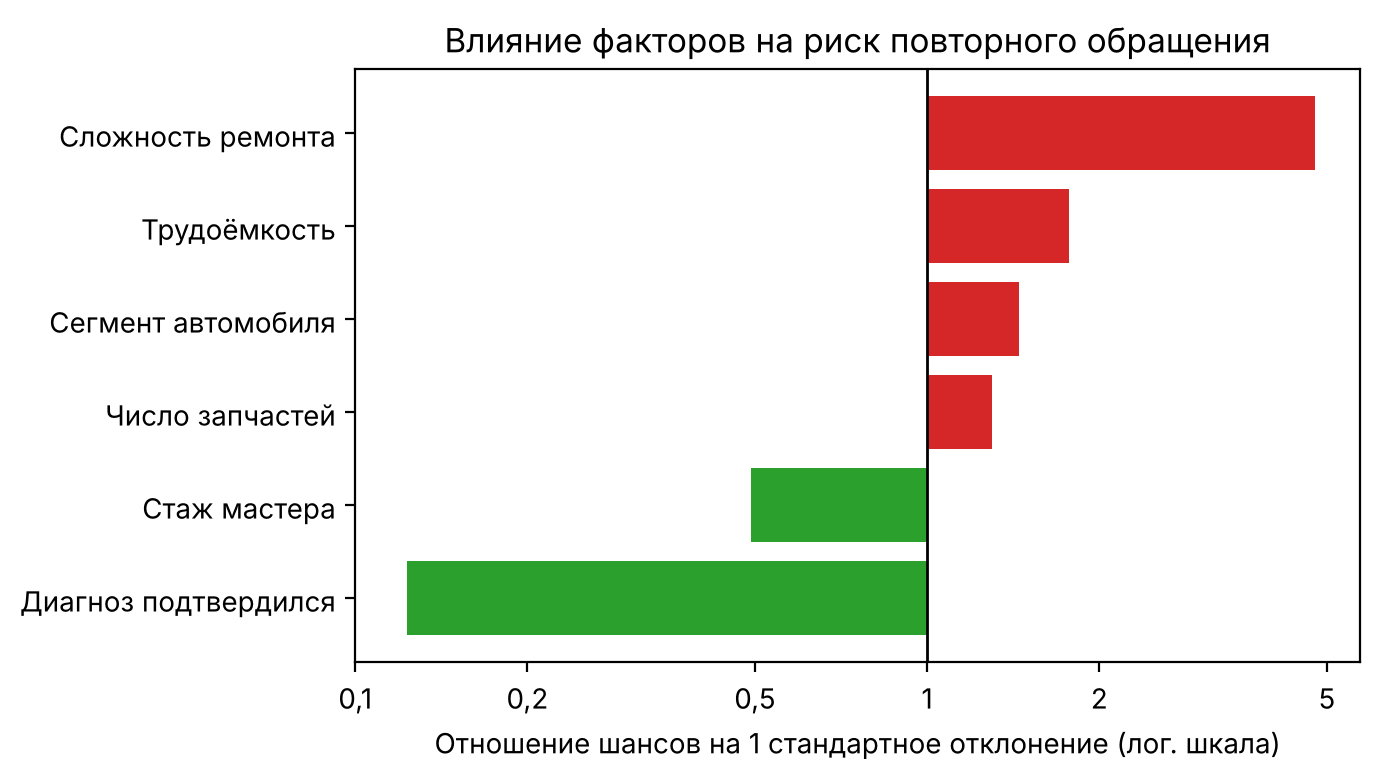

In [18]:
plot_data = factors.sort_values("OR на 1 ст. отклонение")
colors = ["tab:red" if v > 1 else "tab:green" for v in plot_data["OR на 1 ст. отклонение"]]

plt.figure(figsize=(7, 4))
# Столбик идёт от 1 (нет влияния) до значения OR
plt.barh(plot_data["фактор"], plot_data["OR на 1 ст. отклонение"] - 1, left=1, color=colors)
plt.xscale("log")
plt.minorticks_off()
plt.xticks([0.1, 0.2, 0.5, 1, 2, 5], ["0,1", "0,2", "0,5", "1", "2", "5"])
plt.axvline(1, color="black", linewidth=1)
plt.xlabel("Отношение шансов на 1 стандартное отклонение (лог. шкала)")
plt.title("Влияние факторов на риск повторного обращения")
plt.tight_layout()
plt.savefig("pictures/fig2_factors_or.png", dpi=300)
plt.show()

**Рисунок 3.** Сколько машин проверяем и какую долю будущих возвратов ловим при разных порогах.

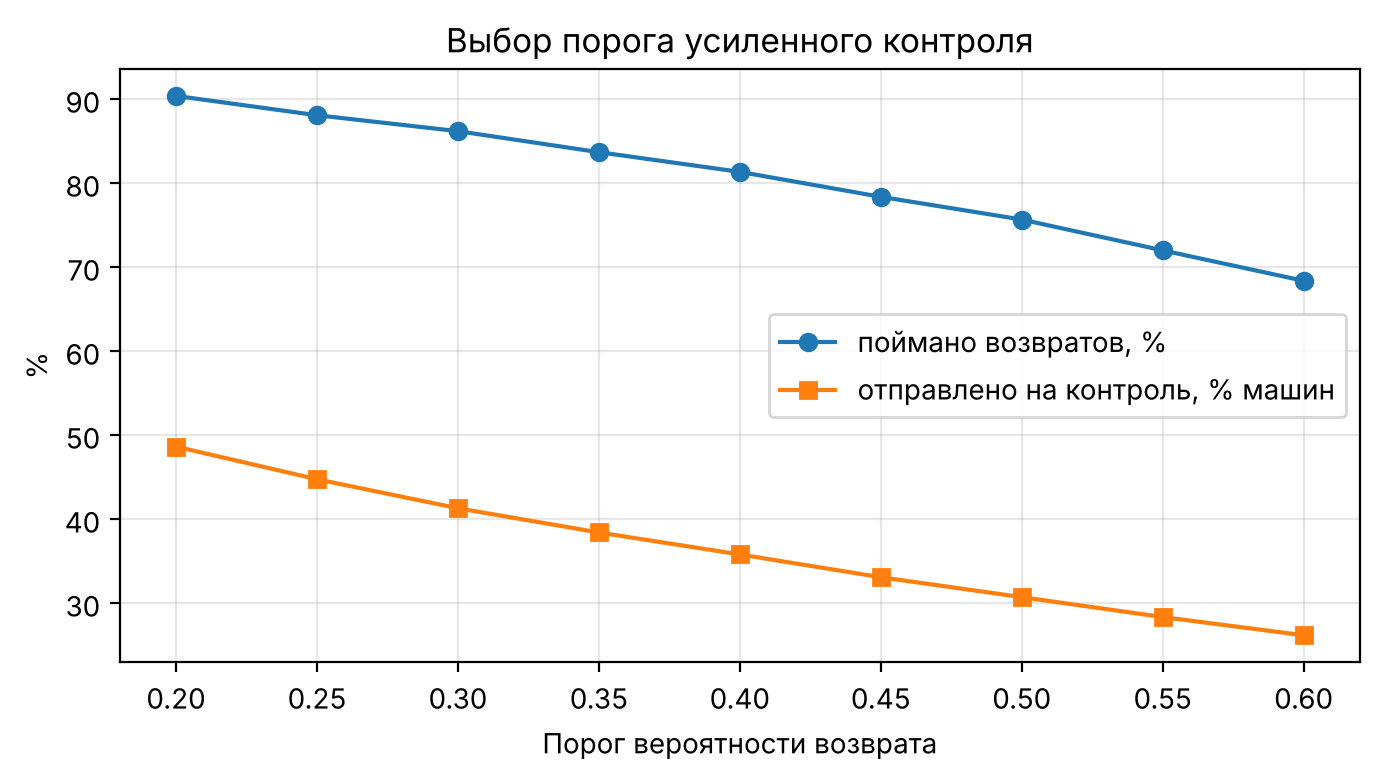

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_table.index, threshold_table["поймано возвратов, %"], "o-",
         label="поймано возвратов, %")
plt.plot(threshold_table.index, threshold_table["проверяем, машин из 100"], "s-",
         label="отправлено на контроль, % машин")
plt.xlabel("Порог вероятности возврата")
plt.ylabel("%")
plt.title("Выбор порога усиленного контроля")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("pictures/fig3_threshold.png", dpi=300)
plt.show()

## 13. Выводы и практические рекомендации

**1. Какой способ выбрать.** Способ А (логистическая регрессия) в среднем по 100 запускам немного точнее способа B
(случайный лес): ROC-AUC 0,920 ± 0,011 против 0,914 ± 0,012. Способ А оказался лучше в 97 запусках из 100, а вероятность
возврата он оценивает точнее в 99 запусках из 100 (Brier 0,099 против 0,105). Разница небольшая (≈0,007 по ROC-AUC):
случайный лес не нашёл в данных ничего сверх того, что улавливает простая регрессия. Поэтому выбираем способ А —
он не хуже по качеству, проще и объясним: по каждому фактору видно, во сколько раз он меняет риск.

При пороге 0,5 способ А ловит 76 % будущих возвратов, способ B — 69 %; зато у B выше доля подтвердившихся тревог
(87 % против 83 %). Это разница в настройке порога, а не в качестве моделей: порог выбирается отдельно (раздел 11).

**2. Что сильнее всего влияет на повторное обращение** (разделы 5 и 9; порядок факторов подтверждает случайный лес, раздел 10):
- **Диагноз не подтвердился в ходе работ** — главный фактор. Такие клиенты возвращаются в 75 % случаев
  (3 машины из 4), при подтверждённом диагнозе — в 15 % (1 из 7). Шансы возврата выше примерно в 90 раз
  (95 %-й интервал: 65–126).
- **Сложность ремонта**: каждый дополнительный балл увеличивает шансы возврата в 1,8 раза.
- **Стаж мастера**: каждый год стажа снижает шансы возврата на 8 %; 10 лет стажа — примерно в 2,3 раза.
- **Трудоёмкость, сегмент автомобиля, число запчастей** влияют слабее, но тоже значимо: +1 нормо-час — шансы ×1,11;
  премиум по сравнению с эконом — шансы ×2,8; +1 запчасть — шансы ×1,16.

**3. Как выбрать порог усиленного контроля** (раздел 11, в среднем по 100 запускам, на 100 закрытых заказ-нарядов):

| Порог | Проверяем машин | Ловим будущих возвратов | Пропускаем возвратов |
|---|---|---|---|
| 0,50 | 31 | 76 % | 8 |
| 0,35 | 38 | 84 % | 5–6 |
| 0,20 | 49 | 90 % | 3 |

Для сравнения: если проверять 38 машин из 100 выборочно, без модели, ловится лишь около 38 % возвратов, а с моделью — 84 %.
Порог задаёт руководитель сервиса исходя из пропускной способности поста контроля. Чем ниже порог, тем дороже
каждый дополнительно пойманный возврат: снижение порога с 0,50 до 0,35 даёт ещё один пойманный возврат примерно на каждые
3 дополнительные проверки, а с 0,35 до 0,20 — уже на каждые 4–5. Если известны стоимость одной проверки и стоимость
повторного ремонта и считать, что проверка устраняет дефект, порог можно рассчитать как
«стоимость проверки / (стоимость проверки + стоимость повторного ремонта)».

**4. Рекомендации для сервиса:**
- если первоначальный диагноз не подтвердился — усиленный контроль назначать всегда, независимо от модели;
- сложные ремонты поручать опытным мастерам: при сложности 7–10 баллов у мастеров со стажем до 5 лет возвращаются
  67 % клиентов, со стажем 20–30 лет — 42 % (раздел 5);
- встроить расчёт вероятности в закрытие заказ-наряда: если вероятность выше выбранного порога, машина
  до выдачи клиенту проходит дополнительную проверку и тест-драйв.

**Ограничения.** Модель построена на одном наборе из 3 000 заказ-нарядов. Перед внедрением её нужно проверить на свежих
данных конкретного сервиса и уточнить порог по фактической загрузке поста контроля.